# Forecasting 3 — Final Assignment — Version 6

**Business context:** Sports retailer  
**Problem:** Predict weekly sales for each store to help with staff and stock planning.  
**Dataset:** `group_03_forecasting_3.csv`  

We follow the six CRISP-DM phases. The numbers and graphs below come from our data and Python code.

## Phase 1 — Business Understanding

Store managers need a sales forecast **before** they order stock and plan staff. Sunday evening is too late. For this assignment, we choose **Thursday before the target week** as the planning day. This is our assumption, not a confirmed company deadline.

For example, on Thursday in week 10, we predict sales for week 11. Week 10 is not finished yet. The latest complete sales week is week 9. This means we must use sales from **at least two weeks before the target week**.

We predict weekly revenue (`sales_eur`) for each store. One row should represent one store-week, identified by `store_id` and `week_start`. We do not have product quantities in the dataset. Revenue forecasts can support general planning, but they cannot tell managers exactly how many products to order or staff members to schedule.

Our original success goal is at least **5% lower MAE than the two-week naive baseline (`lag_2`)**, without worse MAE for any store. We chose this as our own practical improvement target, not as a company rule. We keep this original goal even if later results show that another baseline is stronger. We do not know actual ordering deadlines or business costs, so the company must confirm these assumptions before use.


In [1]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA = Path('group_03_forecasting_3.csv')
if not DATA.exists():
    DATA = Path('/mnt/data/group_03_forecasting_3.csv')
raw = pd.read_csv(DATA)
print('Dataset shape:', raw.shape)
display(raw.head())


Dataset shape: (1065, 11)


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
0,S06,25-11-2024,NONE,0,11.2,10.5,6875,27.82,36396.09,1279.27,medium
1,S02,22-07-2024,none,0,21.6,6.5,9128,19.57,46580.82,2236.76,high
2,S08,04-03-2024,Discount,0,2.9,0.6,7825,38.01,38589.62,1048.21,medium
3,S02,09-03-2026,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
4,S06,02-12-2024,none,1,1.2,0.4,8382,40.54,37143.15,1487.54,medium


## Phase 2 — Data Understanding

We first look at the data to understand what we are trying to predict. Each row should show the sales of one store in one week. Our target is `sales_eur`.

We check how many stores and weeks are in the data. We also look for missing values, repeated store-weeks and differences in weekly sales. This helps us decide what we need to prepare before making a forecast.

We also check which columns we can use on Thursday, before the week we want to predict. We should not use information that is only known after that week has finished.


In [3]:
df = raw.copy()
df['week_start'] = pd.to_datetime(df['week_start'], dayfirst=True, errors='coerce')
print('Date range:', df.week_start.min(), 'to', df.week_start.max())
print('Stores:', df.store_id.nunique(), '| weeks:', df.week_start.nunique())
print('Missing by field:'); display(df.isna().sum().to_frame('missing'))
print('Duplicate store-week rows:', df.duplicated(['store_id','week_start']).sum())
print('Promo raw labels:'); display(df.promo_label.value_counts(dropna=False).to_frame('count'))
print('Sales distribution:'); display(df.sales_eur.describe().to_frame('sales_eur'))
print('Non-positive sales:', (df.sales_eur <= 0).sum())
print('Date parse failures:', df.week_start.isna().sum())
print('Five highest sales rows:')
display(df.nlargest(5,'sales_eur')[['store_id','week_start','sales_eur']])


Date range: 2024-01-01 00:00:00 to 2026-03-30 00:00:00
Stores: 9 | weeks: 118
Missing by field:


,missing
store_id,0
week_start,0
promo_label,71
holiday_week,0
temperature_actual,0
rain_mm_actual,0
footfall_actual,0
average_price_eur,18
sales_eur,0
returns_next_week_eur,0


Duplicate store-week rows: 3
Promo raw labels:


,count
promo_label,
none,470
discount,272
bundle,133
Discount,94
NaN,71
NONE,25


Sales distribution:


,sales_eur
count,1065.000000
mean,36832.336342
std,9816.546981
min,3791.040000
25%,32675.260000
50%,36118.020000
75%,42894.250000
max,169869.006000


Non-positive sales: 0
Date parse failures: 0
Five highest sales rows:


,store_id,week_start,sales_eur
808,S03,2024-10-21,169869.006
462,S09,2024-10-28,166970.214
628,S08,2025-02-24,142447.104
869,S01,2024-04-01,80249.730
459,S09,2025-11-03,51568.510


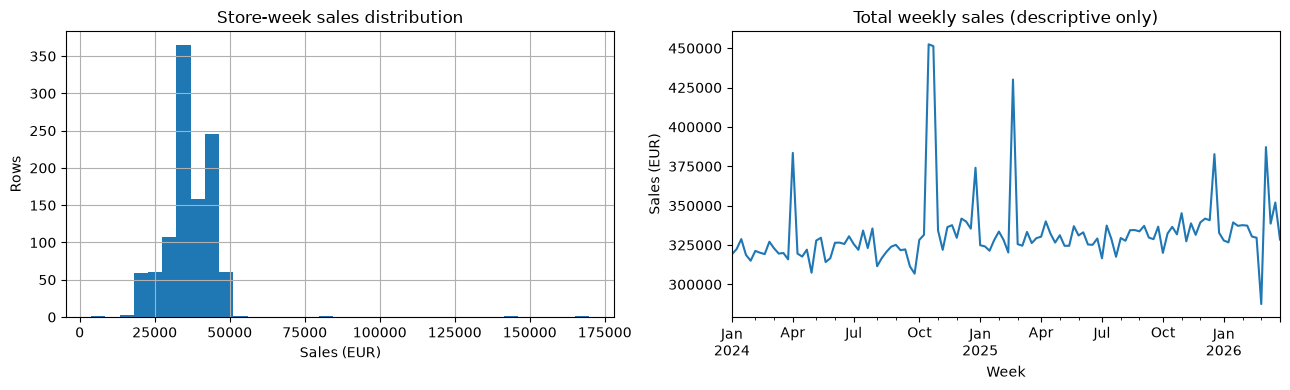

,count,mean,std,min,max
store_id,,,,,
S01,118,23082.44,5828.56,15809.59,80249.73
S02,119,45264.85,2155.83,39702.37,51059.85
S03,119,44741.58,11784.47,38473.75,169869.01
S04,118,35014.10,2198.38,28560.63,39736.14
S05,118,36673.81,2048.00,31185.51,41570.41
S06,118,34242.49,2185.74,29293.19,39723.21
S07,118,31319.16,2150.83,25027.86,36876.30
S08,118,36289.24,10058.92,30639.98,142447.10
S09,119,44658.54,12114.34,3791.04,166970.21


In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
df.sales_eur.hist(ax=axes[0],bins=35)
axes[0].set(title='Store-week sales distribution',xlabel='Sales (EUR)',ylabel='Rows')
df.groupby('week_start').sales_eur.sum().sort_index().plot(ax=axes[1])
axes[1].set(title='Total weekly sales (descriptive only)',xlabel='Week',ylabel='Sales (EUR)')
plt.tight_layout(); plt.show()
display(df.groupby('store_id').sales_eur.agg(['count','mean','std','min','max']).round(2))

### What we found and what this means for Phase 1

**Dataset facts:** The dataset has 1,065 rows, 9 stores and 118 unique weeks. Three store-week keys appear twice. `promo_label` has 71 missing values and `average_price_eur` has 18 missing values. Store revenue levels are different, and the table above shows unusual high and low weeks. The sales-per-visitor check helps us spot values worth investigating, but does not prove an error.

**How this affects our business problem:** Phase 1 asks for one weekly revenue forecast per store. The duplicate keys challenge that requirement, so we must create one row per store-week. Different store sales levels mean we must also check errors for each store. Because we forecast on Thursday before the target week, actual footfall, weather and target-week sales cannot be used as predictors.

**Our assumptions and choices:** Thursday is our proposed planning moment, not a confirmed company deadline. We choose to keep unusual sales values unless they are verified as wrong. We use revenue because the dataset does not provide product quantities; the forecast cannot directly tell managers how many items to order.

In [5]:
# Inspect unusually high and low revenue values. This is a data-quality check only.
inspect_cols = ['store_id','week_start','sales_eur','footfall_actual','promo_label','holiday_week']
unusual = pd.concat([df.nlargest(4,'sales_eur'),df.nsmallest(1,'sales_eur')])[inspect_cols].copy()
unusual['sales_per_visitor'] = (unusual.sales_eur / unusual.footfall_actual).round(2)
print('Unusual high and low store-weeks:')
display(unusual)
print('Median sales per visitor by store:')
display((df.sales_eur / df.footfall_actual).groupby(df.store_id).median().round(2))


Unusual high and low store-weeks:


,store_id,week_start,sales_eur,footfall_actual,promo_label,holiday_week,sales_per_visitor
808,S03,2024-10-21,169869.006,8721,none,0,19.48
462,S09,2024-10-28,166970.214,8509,discount,0,19.62
628,S08,2025-02-24,142447.104,7102,none,0,20.06
869,S01,2024-04-01,80249.730,4138,none,0,19.39
1013,S09,2026-03-02,3791.040,7623,discount,0,0.50


Median sales per visitor by store:


store_id
S01    5.36
S02    4.95
S03    5.07
S04    4.81
S05    5.00
S06    4.79
S07    4.81
S08    4.93
S09    5.00
dtype: float64

## Phase 3 — Data Preparation

We make **three substantive preparation decisions**. For each decision, we show the evidence, technique, before/after check, interpretation and next decision. The code directly below prints the checks.

**Decision 1 — Duplicate store-weeks**
- **Evidence:** Phase 2 finds 1,065 source rows and 3 extra duplicate store-week rows (6 records involved).
- **Technique:** As discussed with the teacher, group by `store_id` and `week_start` and take the **mean of `sales_eur` only**. `returns_next_week_eur` is not averaged or used.
- **Before/after:** The code shows 1,065 rows before and 1,062 after, with zero repeated keys. In each duplicate pair, `sales_eur` is the same, so its mean does not change the recorded revenue.
- **Interpretation:** We now have one target value per store-week. This does not tell us which conflicting returns value is correct.
- **Next decision:** Use the resulting store-week table for the forecast and ask the data owner to verify duplicate records before operational use.

**Decision 2 — Missing and unusual values**
- **Evidence:** There are 71 missing promotion labels, 18 missing average prices, and some unusually high and low sales values.
- **Technique:** Standardise promotion spelling and fill missing labels with `unknown`. Exclude promotions and average price from predictors because their availability by Thursday is not confirmed. Keep unusual revenue values in the main analysis; inspect them instead of silently deleting them.
- **Before/after:** The code prints promotion categories after standardisation and the original missing-price count. The revenue target is not changed by this decision.
- **Interpretation:** This avoids assuming unavailable target-week information. Unusual values may be genuine or errors; the dataset alone cannot prove which.
- **Next decision:** Investigate unusual sales with the data owner. A **training-only sensitivity check evaluated on validation**, shown later, measures whether unusual training targets affect model performance; it is not used to select a better-looking model from test results.

**Decision 3 — Available historical features**
- **Evidence:** On Thursday, the current week is unfinished, so the target week's `lag_1` sales are not yet known. One row per store-week is required for time shifts.
- **Technique:** Sort by store and week, create `lag_2`, `lag_3`, `lag_5`, `lag_9`, a four-completed-week rolling mean, and calendar features. Exclude actual target-week footfall, weather, returns and other future information. We leave `holiday_week` out rather than selecting it after seeing test results.
- **Before/after:** The code prints sample shifted rows and the number of complete feature rows: 1,062 prepared store-weeks become 981 modelling rows because the first weeks lack enough history.
- **Interpretation:** All selected sales inputs come from fully completed weeks before the Thursday prediction.
- **Next decision:** Use time-ordered training, validation and test periods. Any feature changes must be decided using training and validation, never by inspecting which choice wins on test.

In [6]:
before = len(df)
conflicts = df.loc[df.duplicated(['store_id','week_start'],keep=False)].sort_values(['store_id','week_start'])
print('Duplicate-key source rows:'); display(conflicts)
df['promo_clean'] = df.promo_label.astype('string').str.strip().str.lower().fillna('unknown')
print('Promo categories after standardization:'); display(df.promo_clean.value_counts())
print('Missing prices before exclusion:', df.average_price_eur.isna().sum())
# Explicit provisional deduplication; non-target fields are not used as predictors.
panel = (df.groupby(['store_id','week_start'],as_index=False)
         .agg(sales_eur=('sales_eur','mean'))
         .sort_values(['store_id','week_start']).reset_index(drop=True))
assert not panel.duplicated(['store_id','week_start']).any()
print('Rows before / after:', before, len(panel))
print('Key duplicates after:',panel.duplicated(['store_id','week_start']).sum())
print('Dates per store:',panel.groupby('store_id').week_start.nunique().to_dict())

Duplicate-key source rows:


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
3,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
151,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,2984.26,high
220,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,1281.35,high
760,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,2950.96,high
848,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,654.19,high
993,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,1361.44,high


Promo categories after standardization:


promo_clean
none        495
discount    366
bundle      133
unknown      71
Name: count, dtype: Int64

Missing prices before exclusion: 18
Rows before / after: 1065 1062
Key duplicates after: 0
Dates per store: {'S01': 118, 'S02': 118, 'S03': 118, 'S04': 118, 'S05': 118, 'S06': 118, 'S07': 118, 'S08': 118, 'S09': 118}


In [7]:
panel['week_number'] = panel.week_start.dt.isocalendar().week.astype(int)
panel['month'] = panel.week_start.dt.month
panel['week_sin'] = np.sin(2*np.pi*panel.week_number/52.18)
panel['week_cos'] = np.cos(2*np.pi*panel.week_number/52.18)
g = panel.groupby('store_id',sort=False)['sales_eur']
for lag in [2,3,5,9]:
    panel[f'lag_{lag}'] = g.shift(lag)
panel['trailing_4_mean'] = panel.groupby('store_id',sort=False)['sales_eur'].transform(lambda x: x.shift(2).rolling(4).mean())
print('Before/after check: the first forecast uses week t-2 or older:')
display(panel.loc[panel.store_id == panel.store_id.iloc[0],['week_start','sales_eur','lag_2','lag_3','trailing_4_mean']].head(12))
model_data = panel.dropna(subset=['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']).copy()
print('Rows available after creating older sales features:',len(model_data))
assert model_data[['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']].notna().all().all()


Before/after check: the first forecast uses week t-2 or older:


,week_start,sales_eur,lag_2,lag_3,trailing_4_mean
0,2024-01-01,21393.60,NaN,NaN,NaN
1,2024-01-08,18429.52,NaN,NaN,NaN
2,2024-01-15,21566.87,21393.60,NaN,NaN
3,2024-01-22,20068.53,18429.52,21393.60,NaN
4,2024-01-29,19925.60,21566.87,18429.52,NaN
5,2024-02-05,20948.10,20068.53,21566.87,20364.6300
6,2024-02-12,18963.15,19925.60,20068.53,19997.6300
7,2024-02-19,21453.58,20948.10,19925.60,20627.2750
8,2024-02-26,22086.19,18963.15,20948.10,19976.3450
9,2024-03-04,23120.25,21453.58,18963.15,20322.6075


Rows available after creating older sales features: 981


## Phase 4 — Modelling

We predict revenue on **Thursday before the target week**. We cannot use sales from the current unfinished week. We compare two simple methods with a machine learning model:

- **Two-week naive baseline (`lag_2`):** use the revenue from two weeks before the target week. This is the baseline used in our original 5% success criterion.
- **Four-week average (`trailing_4_mean`):** use the average revenue from the four most recent fully completed weeks. This smooths out week-to-week changes.
- **HistGradientBoosting model:** use older sales, the store and the time of year. `lag_5` and `lag_9` give the model information about older sales patterns, but we have not proved that these particular lags are optimal. We test 4, 8 and 16 maximum leaf nodes. Leaf nodes are the endpoints of the small decision trees; more leaf nodes allow more detailed patterns but do not guarantee better results.

We train on older dates, choose the candidate settings using later **validation** dates, and evaluate on the final **test** dates. The test is a rolling Thursday forecast: earlier completed weeks can be used when they become available. It is not one fixed forecast for all test weeks.

**Important:** choices about features, unusual values and model settings must be based on training and validation data, not on the final test results. We use the test period for final evaluation and diagnostics, not to select a better-looking model afterwards.


In [8]:
dates = np.array(sorted(model_data.week_start.unique()))
cut1, cut2 = dates[int(len(dates)*0.65)], dates[int(len(dates)*0.80)]
train = model_data[model_data.week_start < cut1].copy()
val = model_data[(model_data.week_start >= cut1)&(model_data.week_start < cut2)].copy()
test = model_data[model_data.week_start >= cut2].copy()
print('Cutoffs:',pd.Timestamp(cut1).date(),pd.Timestamp(cut2).date())
for label,part in [('train',train),('validation',val),('test',test)]:
    print(label,len(part),part.week_start.min().date(),part.week_start.max().date())
assert train.week_start.max() < val.week_start.min() < test.week_start.min()
base_features = ['lag_2','lag_3','lag_5','lag_9','trailing_4_mean','month','week_sin','week_cos']
store_columns = ['store_'+s for s in sorted(model_data.store_id.unique())]
def features(frame):
    x = frame[base_features].copy()
    for s,c in zip(sorted(model_data.store_id.unique()),store_columns):
        x[c] = (frame.store_id == s).astype(int)
    return x

def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'MAE_EUR':mean_absolute_error(y,p),
            'RMSE_EUR':np.sqrt(mean_squared_error(y,p)),
            'WAPE_pct':100*np.abs(y-p).sum()/np.abs(y).sum(),
            'Bias_EUR':np.mean(p-y)}

results=[]
for depth in [2,3,4]:
    candidate=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=2**depth,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
    candidate.fit(features(train),train.sales_eur)
    pred=candidate.predict(features(val))
    results.append({'max_leaf_nodes':2**depth,**metrics(val.sales_eur,pred)})
validation_results=pd.DataFrame(results).sort_values('MAE_EUR')
print('Candidate validation results:');display(validation_results.round(2))
print('Simple baselines on validation:')
display(pd.DataFrame({'Two-week naive':metrics(val.sales_eur,val.lag_2), 'Four-week average':metrics(val.sales_eur,val.trailing_4_mean)}).T.round(2))
best_leaves=int(validation_results.iloc[0].max_leaf_nodes)
print('Chosen leaves using validation only:',best_leaves)

Cutoffs: 2025-07-07 2025-11-03
train 630 2024-03-04 2025-06-30
validation 153 2025-07-07 2025-10-27
test 198 2025-11-03 2026-03-30


Candidate validation results:


,max_leaf_nodes,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
2,16,2435.69,3572.14,6.64,403.80
1,8,2503.44,3665.35,6.82,478.39
0,4,2727.68,3985.93,7.43,726.57


Simple baselines on validation:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
Two-week naive,2151.15,2659.41,5.86,-91.78
Four-week average,1716.92,2159.88,4.68,-92.34


Chosen leaves using validation only: 16


### Validation-only sensitivity check (not a final model choice)

We investigate whether unusually high or low **training** revenue values influence the candidate model. We calculate each store's typical revenue per visitor from **training data only**. For this diagnostic check, we flag training rows with less than half or more than twice that typical ratio. These are investigation thresholds, **not proof of errors**. We train a second model without those training targets and compare both versions on **validation only**. The validation results are reported as a sensitivity check; we keep the original candidate settings and do not choose a version because of its test score. Removing a training target does not remove that value from later lag features, which limits this check.

In [9]:
# Validation-only sensitivity analysis: thresholds estimated from training weeks only.
# Use the original source for footfall; duplicated source keys have identical footfall.
footfall_lookup = df.groupby(['store_id','week_start']).footfall_actual.first()
train_footfall = np.array([footfall_lookup.loc[(s,w)] for s,w in zip(train.store_id,train.week_start)])
ratio = train.sales_eur.to_numpy() / train_footfall
reference = pd.Series(ratio,index=train.index).groupby(train.store_id).median()
relative = ratio / train.store_id.map(reference).to_numpy()
flagged_train = (relative > 2) | (relative < 0.5)
print('Flagged training rows (for sensitivity only):',int(flagged_train.sum()))
display(train.loc[flagged_train,['store_id','week_start','sales_eur']])
original_validation_model = HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,learning_rate=0.05,l2_regularization=10,random_state=42)
original_validation_model.fit(features(train),train.sales_eur)
sensitivity_validation_model = HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,learning_rate=0.05,l2_regularization=10,random_state=42)
sensitivity_validation_model.fit(features(train.loc[~flagged_train]),train.loc[~flagged_train,'sales_eur'])
sensitivity_results = pd.DataFrame({
 'Original candidate':metrics(val.sales_eur,original_validation_model.predict(features(val))),
 'Candidate excluding flagged training targets':metrics(val.sales_eur,sensitivity_validation_model.predict(features(val))),
 'Four-week average':metrics(val.sales_eur,val.trailing_4_mean)}).T
print('Sensitivity comparison on validation only (test not used):')
display(sensitivity_results.round(2))
print('This is diagnostic. The final candidate is still selected using the original validation procedure.')

Flagged training rows (for sensitivity only): 4


,store_id,week_start,sales_eur
13,S01,2024-04-01,80249.730
278,S03,2024-10-21,169869.006
886,S08,2025-02-24,142447.104
987,S09,2024-10-28,166970.214


Sensitivity comparison on validation only (test not used):


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
Original candidate,2435.69,3572.14,6.64,403.80
Candidate excluding flagged training targets,1738.51,2262.50,4.74,-552.07
Four-week average,1716.92,2159.88,4.68,-92.34


This is diagnostic. The final candidate is still selected using the original validation procedure.


**Interpretation:** This check asks how much the validation error changes when suspicious *training targets* are excluded. It does not establish that those records are wrong. The original values can still affect lag inputs in later rows. We do not use the held-out test set to decide whether to remove observations or add `holiday_week`. Those would be new choices requiring training and validation, followed by a genuinely untouched final test.

## Phase 5 — Evaluation

We compare the candidate model with **both simple baselines** on the held-out test weeks. We check MAE, RMSE, WAPE, bias and results for each store. Lower MAE is better. Here **bias = prediction minus actual revenue**, so negative bias means that revenue was predicted too low.

A forecast that is **too low** may lead to insufficient planning, while a forecast that is **too high** may lead to unnecessary costs. Revenue does not directly measure the number of products or workers needed, and we have no cost data. These are possible business effects, not measured losses.

We also investigate unusual sales values. We do not call them errors without confirmation from the data owner. Any comparison made on the test period is **diagnostic only**: we do not use it to choose new features, remove records or tune the final model. Those choices would need to be tested on validation data first.


Final held-out test results:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR,MAE_vs_naive_pct
Naive two weeks ago,2749.18,5159.28,7.41,-61.31,0.00
Four-week average,2183.66,3993.05,5.88,-78.29,-20.57
Candidate model,2437.18,4159.34,6.56,-252.07,-11.35


Store-level held-out results:


,store_id,naive_MAE,candidate_MAE,candidate_WAPE_pct,candidate_bias_EUR,MAE_change_pct
0,S01,1674.10,1798.54,7.38,-863.27,7.43
1,S02,2596.70,2653.73,5.73,-1541.64,2.20
2,S03,1790.32,2347.04,5.18,-1022.39,31.10
3,S04,2743.57,2032.86,5.79,-185.42,-25.90
4,S05,2165.15,2643.33,7.07,623.74,22.09
5,S06,2047.84,2297.00,6.51,-322.13,12.17
6,S07,2537.07,1800.21,5.89,1034.62,-29.04
7,S08,2755.25,1849.15,5.15,414.27,-32.89
8,S09,6432.58,4512.78,10.28,-406.40,-29.85


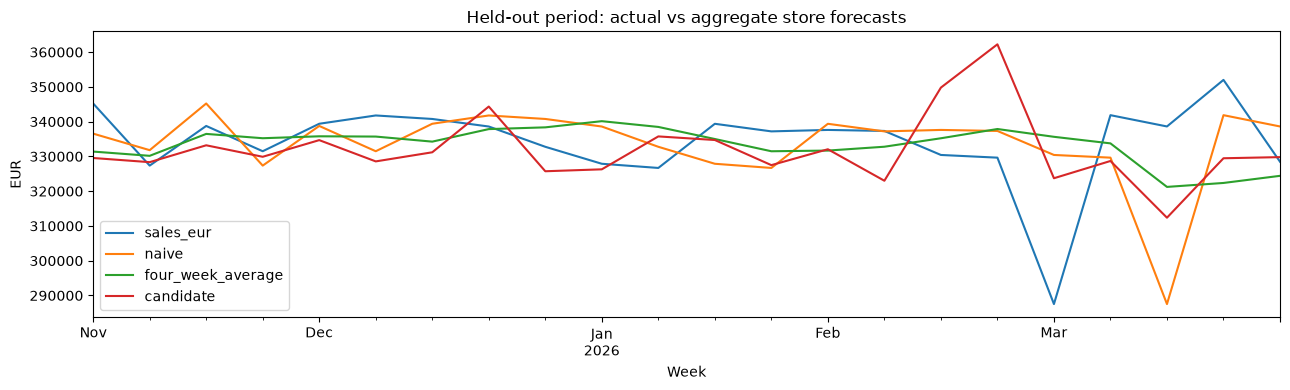

In [10]:
trainval=pd.concat([train,val],ignore_index=True)
final_model=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
final_model.fit(features(trainval),trainval.sales_eur)
eval_df=test[['store_id','week_start','sales_eur']].copy()
eval_df['naive']=test.lag_2.to_numpy()
eval_df['four_week_average']=test.trailing_4_mean.to_numpy()
eval_df['candidate']=final_model.predict(features(test))
comparison=pd.DataFrame({'Naive two weeks ago':metrics(eval_df.sales_eur,eval_df.naive),
                         'Four-week average':metrics(eval_df.sales_eur,eval_df.four_week_average),
                         'Candidate model':metrics(eval_df.sales_eur,eval_df.candidate)}).T
comparison['MAE_vs_naive_pct']=100*(comparison.MAE_EUR/comparison.loc['Naive two weeks ago','MAE_EUR']-1)
print('Final held-out test results:');display(comparison.round(2))
rows=[]
for store,grp in eval_df.groupby('store_id'):
    a=metrics(grp.sales_eur,grp.naive);b=metrics(grp.sales_eur,grp.candidate)
    rows.append({'store_id':store,'naive_MAE':a['MAE_EUR'],'candidate_MAE':b['MAE_EUR'],
                 'candidate_WAPE_pct':b['WAPE_pct'],'candidate_bias_EUR':b['Bias_EUR'],
                 'MAE_change_pct':100*(b['MAE_EUR']/a['MAE_EUR']-1)})
store_results=pd.DataFrame(rows)
print('Store-level held-out results:');display(store_results.round(2))
fig,ax=plt.subplots(figsize=(13,4))
weekly=eval_df.groupby('week_start')[['sales_eur','naive','four_week_average','candidate']].sum()
weekly.plot(ax=ax);ax.set(title='Held-out period: actual vs aggregate store forecasts',ylabel='EUR',xlabel='Week');plt.tight_layout();plt.show()

In [11]:
naive_mae=comparison.loc['Naive two weeks ago','MAE_EUR']
rolling_mae=comparison.loc['Four-week average','MAE_EUR']
model_mae=comparison.loc['Candidate model','MAE_EUR']
improvement=100*(naive_mae-model_mae)/naive_mae
model_vs_rolling=100*(model_mae/rolling_mae-1)
store_worse=(store_results.MAE_change_pct>0).sum()
print(f'Test MAE improvement versus two-week naive: {improvement:.1f}%.')
print(f'Candidate MAE relative to four-week average: {model_vs_rolling:+.1f}% (positive means worse).')
print(f'Stores with worse candidate MAE than two-week naive: {store_worse} of {len(store_results)}.')
print('Original success criterion: at least 5% lower MAE than two-week naive and no store worse.')
print('Original criterion met:',improvement >= 5 and store_worse == 0)
if model_mae >= rolling_mae:
    print('Business decision: do not deploy the current candidate. The four-week average is stronger on this held-out period. Review data quality and return to preparation/validation.')
elif improvement >= 5 and store_worse == 0:
    print('Business decision: a controlled shadow pilot may be considered, with manager review.')
else:
    print('Business decision: do not deploy the current candidate. Review store-level errors and validation evidence first.')
print('Test-period comparisons are final evaluation and diagnostics, not a reason to tune the model on test data.')


Test MAE improvement versus two-week naive: 11.3%.
Candidate MAE relative to four-week average: +11.6% (positive means worse).
Stores with worse candidate MAE than two-week naive: 5 of 9.
Original success criterion: at least 5% lower MAE than two-week naive and no store worse.
Original criterion met: False
Business decision: do not deploy the current candidate. The four-week average is stronger on this held-out period. Review data quality and return to preparation/validation.
Test-period comparisons are final evaluation and diagnostics, not a reason to tune the model on test data.


### Interpretation and remaining limits

The test comparison above shows whether the machine learning model improves on the original two-week baseline **and** on the four-week average. The original 5% criterion stays unchanged; we do not rewrite it after seeing the results. A lower error for the four-week average would mean that a simpler method is more useful on this test period.

The store-level table shows which stores have worse model MAE than the two-week baseline. Overall improvement does not guarantee improvement for every store. The bias column uses **prediction minus actual**, so negative values mean underforecasting. We should investigate store-level differences and unusual weeks before making operational decisions.

The company still needs to confirm that Thursday is early enough for stock and staffing decisions. We have only one final test period. Further time-based validation and confirmation of suspicious records would make our conclusions more reliable. If the company confirms that promotions are planned before Thursday, a future version could evaluate them using validation data.


### Facts, assumptions and our choices

- **Dataset facts:** Nine stores, weekly `sales_eur`, missing fields, duplicate store-week records, and the observed validation and test metrics come from the supplied data and code.
- **Business assumptions:** Thursday is early enough for planning; managers can use revenue forecasts to support decisions; the company can check questionable records. These points need confirmation.
- **Our analytical choices:** Forecast revenue rather than units, use `lag_2` and the four-week mean as baselines, average duplicate `sales_eur`, exclude unavailable features, use chronological splits, and keep the original 5% goal. We do not change these choices after seeing test performance.

The final test is used to **evaluate and make a business recommendation**, not to choose new features, thresholds or model settings. Any future model revision needs a new time-based validation and a fresh final evaluation.

## Phase 6 — Deployment / Next Iteration

**Current decision:** do not automatically use the machine learning model for stock or staffing decisions. We should first compare it with the stronger simple baseline, investigate unusual sales values and confirm the data with the data owner. This is a design for a possible future version, not a claim that the current model is ready.

We would produce a forecast on **Thursday** for the next week, using only completed sales weeks. The retailer must confirm that this is early enough. Managers can review the forecast, compare it with the four-week average and record any override and its reason. Revenue supports general planning, but cannot directly determine exact product quantities or staffing levels.

Before every forecast, we would check for missing data, duplicated store-weeks and unusually high or low sales. We would save forecasts before the target week and compare them with actual revenue afterwards. We would monitor MAE and bias for each store and overall. **Bias is prediction minus actual.** For a future model, we would check that its bias is not more negative than the four-week average's bias over the same weeks; this is a proposed safeguard, not a proven business threshold. MAE must also be checked because bias alone can hide large errors.

We would use a **shadow pilot** for an improved model: record its forecasts without letting them automatically change real orders or staffing. An initial eight-week review gives more observations than four weeks, but is still limited. If the candidate performs worse than the four-week average over the agreed monitoring period, or if important data is unreliable, we use the simple baseline and investigate. We would **review the model and data every month** and **trigger retraining** if the candidate has higher MAE than the four-week average over the agreed monitoring window, if store-level errors repeatedly worsen, or if there is a major change in sales patterns. We would retrain only after checking data quality and validate the updated model on later weeks before considering another shadow pilot. Monthly review is our proposed schedule, not a confirmed company rule. Managers always keep the final decision.


## Individual Understanding

**Tijn:**

In our previous assignments, I sometimes made conclusions too quickly without looking at the data carefully enough. I learned that it is important to explain what the data actually shows instead of making assumptions. In this assignment, I tried to improve this by looking more closely at the differences between stores and being more careful when explaining patterns in sales. I also learned that we need to be clear about when we make our predictions. If we predict sales too late, managers might not have enough time to plan their stock and staff. This assignment helped me understand that we should not only focus on making good predictions, but also on making sure the business can actually use them.

**Jayden:**

From our previous assignments, I learned that we need to be more careful when explaining the results of our data analysis. For example, when we see that sales are higher during promotions, this does not automatically mean that promotions caused the increase. In this assignment, I tried to improve this by focusing more on what the data actually tells us. I also learned that it is important to understand the business problem before starting with the Python code. We first need to know what we want to predict, when we need the prediction and how the business will use it. This helped me understand why we need to make clear choices and explain them throughout the assignment.

**Daniel:**

In our previous assignment, we replaced one extreme sales value without checking whether it was really wrong, and we calculated the limit for unusual values on the full dataset before splitting the data. I learned that you have to investigate a strange value before you change it, and that every rule you learn from the data should come from the training period only. In this assignment, I compared the extreme weeks with footfall. Those weeks had a normal number of visitors but about four times the normal revenue per visitor, which suggests a recording error, although it does not prove one. When we left these four values out of training, the validation error dropped from about 2,560 to 1,750 euros, which shows how much a few records can affect a model. I also learned to compare a model with more than one simple baseline. Our model beat the two-week baseline, but the four-week average was better, so the right business decision was not to deploy it yet.